# 11. Stop-loss recovery and blacklist diagnostics — zero costs

Analyze **all stopped-out pairs in the saved best-Sharpe configuration**, using the same winner selection as notebooks 6–10. A pair-window is the unit of analysis: the existing permanent blacklist allows at most one stop per pair per window. Repeated ticker pairs in different windows remain separate events.

We use saved daily z-scores, with formation beta, mean, and standard deviation frozen. Follow-up ends at the last recorded session of the **same trading window**, never in a later window or the reserved holdout. The primary clock starts strictly **after the stop signal**; a sensitivity starts on the actual next-close stop execution, when the pair is flat.

Primary recovery means an observed close **inside ±4σ** (strictly <4, matching eligibility below the stop), **inside ±1.5σ**, or **inside ±0.5σ** (≤ for the latter two). Counts are cumulative and overlap. We also count directional crossings toward the mean, because the engine's mean-reversion exit can recognize an overshoot across zero without an observed close inside the absolute band. No intraday path is inferred.

“Never below 4σ” means no observed return before window end; this alone does **not** prove a permanent blow-up. We separately measure further divergence, final distance, and limited remaining follow-up. These are descriptive diagnostics of an already selected research sample, not a performance comparison of replacement strategies.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RUN_ID = None
base = ROOT / 'outputs/joint_grid_search_zero_cost'
runs = sorted(p.parent for p in base.glob('*/grid_summary.csv'))
if RUN_ID is None:
    if len(runs) != 1:
        raise ValueError(f'Set RUN_ID to one of {[p.name for p in runs]}')
    run = runs[0]
else:
    run = base / RUN_ID
summary = pd.read_csv(run / 'grid_summary.csv')
complete = summary.loc[summary.Status.eq('complete') & np.isfinite(summary['Sharpe Ratio'])]
if complete.empty:
    raise ValueError('No completed strategy with finite Sharpe.')
winner = complete.sort_values('Sharpe Ratio', ascending=False, kind='stable').iloc[0]
folder = run / Path(winner['Output Folder']).name
params = json.loads((folder / 'parameters.json').read_text())
assert params['cost_bps_per_leg'] == 0
trades = pd.read_csv(folder / 'trades.csv')
for col in ['Entry Date', 'Exit Signal Date', 'Exit Date']:
    trades[col] = pd.to_datetime(trades[col])
daily = pd.read_csv(folder / 'pair_daily.csv.gz', parse_dates=['Date'])
windows = pd.read_csv(folder / 'window_summary.csv').set_index('Window')
for col in ['Trading Start', 'Trading End Exclusive']:
    windows[col] = pd.to_datetime(windows[col])
KEYS = ['Window', 'A', 'B']
assert not daily.duplicated(KEYS + ['Date']).any()
assert np.isfinite(daily.z).all()
assert daily.Date.max() < pd.Timestamp('2023-08-25')
paths = {key: g.sort_values('Date').set_index('Date') for key, g in daily.groupby(KEYS)}
stops = trades.loc[trades['Exit Reason'].eq('Stop loss')].copy().reset_index(drop=True)
assert not stops.duplicated(KEYS).any()
if stops.empty:
    raise ValueError('The selected configuration has no executed stop-loss trades.')
OUT = ROOT / 'outputs/blacklist_diagnostics_zero_cost' / run.name / folder.name
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .2,
                     'axes.spines.top': False, 'axes.spines.right': False})
figures = []
def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / (name + '.png'), dpi=150, bbox_inches='tight')
    figures.append(name)
    plt.show()
print(f"Run {run.name}; saved Sharpe {winner['Sharpe Ratio']:.4f}")
print('Parameters:', params)
print(f'{len(stops)} stops / {len(trades)} trades; {len(daily.groupby(KEYS))} selected pair-windows')


Run cb64c19613e1e11beb71; saved Sharpe 0.3594
Parameters: {'formation_months': 18, 'trading_months': 6, 'correlation_threshold': 0.8, 'eg_significance': 0.01, 'entry_z': 1.5, 'exit_z': 0.5, 'stop_z': 4.0, 'run_id': 'cb64c19613e1e11beb71', 'cost_bps_per_leg': 0.0, 'initial_capital': 100000.0}
54 stops / 212 trades; 130 selected pair-windows


## Recovery counts and event-level audit

Each row below retains the first recovery date and session lag for every threshold, the number of remaining sessions, and the stop and end-of-window distances. Session 1 is the first saved session after the signal. The execution-clock sensitivity includes the execution close (lag zero), since it is the first close when the pair is flat. All events have complete saved follow-up **to their own window end**, but the time available differs.

An additional audit checks blacklist activations that did not become a recorded stop exit: the engine prioritizes forced window-end liquidation over a pending stop on the last session. Those are shown separately and excluded from the executed-stop population.

,Count,Share of all stops,Execution-clock count
Outcome,,,
Returned inside 4σ,45,83.3%,45
Returned to ±1.5σ,22,40.7%,22
Returned to ±0.5σ,15,27.8%,15
Never returned inside 4σ,9,16.7%,9


,Event,Window,Pair,Stop signal,Remaining sessions after signal,Lag 4,Lag 1.5,Lag 0.5,Peak abs z,Final abs z,Never below 4
0,0,1,DTE / PNW,2016-12-02,19,2.0,NaN,NaN,5.236051,4.398054,False
1,1,1,ES / SO,2016-08-26,87,20.0,64.0,79.0,4.845014,0.365665,False
2,2,1,AEP / PCG,2016-08-19,92,1.0,NaN,NaN,4.661609,3.429573,False
3,3,1,DTE / PCG,2016-12-02,19,1.0,NaN,NaN,4.660812,3.600365,False
4,4,1,C / USB,2016-11-09,35,NaN,NaN,NaN,7.917498,7.436260,True
5,5,1,FITB / USB,2016-12-09,14,1.0,NaN,NaN,4.011064,3.642949,False
6,6,1,HBAN / USB,2016-11-09,35,NaN,NaN,NaN,6.273435,5.669476,True
7,7,1,KEY / USB,2016-12-01,20,1.0,NaN,NaN,5.618380,4.991996,False
8,8,1,USB / ZION,2016-12-16,9,1.0,NaN,NaN,4.167480,3.681764,False
9,9,1,PNW / WEC,2016-11-11,33,5.0,NaN,NaN,5.045958,4.510271,False


Blacklist activations without an executed stop exit: 0


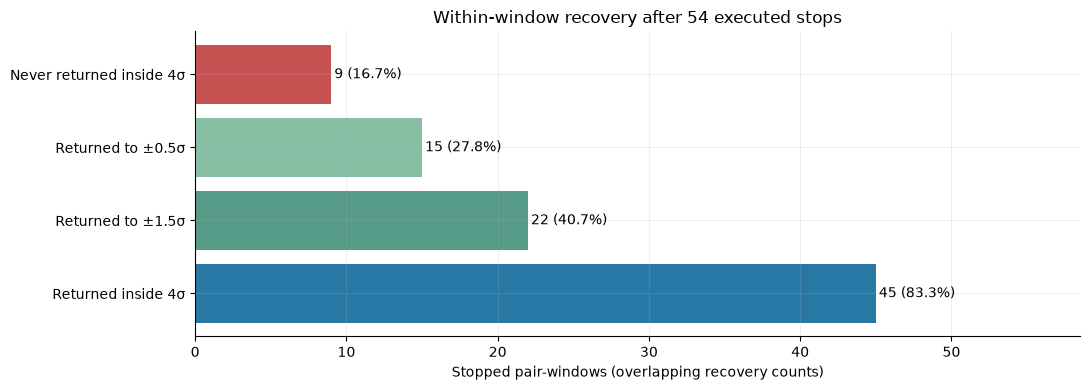

In [2]:
THRESHOLDS = [4.0, 1.5, 0.5]
def band(z, threshold):
    return np.abs(z) < threshold if threshold == 4.0 else np.abs(z) <= threshold

def event_statistics(clock):
    rows = []
    for event, t in stops.iterrows():
        key = tuple(t[k] for k in KEYS)
        p = paths[key]
        w = windows.loc[t.Window]
        assert (p.index >= w['Trading Start']).all() and (p.index < w['Trading End Exclusive']).all()
        signal, execution = t['Exit Signal Date'], t['Exit Date']
        assert pd.notna(signal) and signal < execution
        np.testing.assert_allclose(p.loc[signal, 'z'], t['Exit Signal z'], atol=1e-10)
        np.testing.assert_allclose(p.loc[execution, 'z'], t['Exit z'], atol=1e-10)
        assert p.loc[signal, 'Blacklisted']
        assert p.loc[p.index >= execution, 'Position'].eq(0).all()
        assert p.loc[p.index >= signal, 'Blacklisted'].all()
        anchor = signal if clock == 'signal' else execution
        follow = p.loc[p.index > signal] if clock == 'signal' else p.loc[p.index >= execution]
        lag = np.arange(1, len(follow)+1) if clock == 'signal' else np.arange(len(follow))
        signed = np.sign(t['Exit Signal z']) * follow.z
        r = {'Event': event, **{k: t[k] for k in KEYS}, 'Pair': ' / '.join(sorted([t.A, t.B])),
             'Stop signal': signal, 'Stop execution': execution, 'Window end': p.index[-1],
             'Clock': clock, 'Follow-up observations': len(follow),
             'Remaining sessions after signal': int((p.index > signal).sum()),
             'Stop abs z': abs(t['Exit Signal z']), 'Execution abs z': abs(t['Exit z']),
             'Final abs z': abs(p.z.iloc[-1]), 'Peak abs z': follow.z.abs().max(),
             'Minimum abs z': follow.z.abs().min(), 'Stop P&L ($)': t['Net P/L ($)']}
        for h in THRESHOLDS:
            label = f'{h:g}'
            hit = np.flatnonzero(band(follow.z.to_numpy(), h))
            crossing = np.flatnonzero((signed < h if h == 4 else signed <= h).to_numpy())
            r[f'Recovered {label}'] = bool(len(hit))
            r[f'First date {label}'] = follow.index[hit[0]] if len(hit) else pd.NaT
            r[f'Lag {label}'] = int(lag[hit[0]]) if len(hit) else np.nan
            r[f'Directional crossing {label}'] = bool(len(crossing))
        r['Never below 4'] = not r['Recovered 4']
        r['Further divergence >= 1 sigma'] = r['Peak abs z'] >= r['Stop abs z'] + 1
        rows.append(r)
    return pd.DataFrame(rows)

events = event_statistics('signal')
execution_events = event_statistics('execution')
assert events['Recovered 0.5'].le(events['Recovered 1.5']).all()
assert events['Recovered 1.5'].le(events['Recovered 4']).all()
rows = []
for label, col in [('Returned inside 4σ', 'Recovered 4'), ('Returned to ±1.5σ', 'Recovered 1.5'),
                   ('Returned to ±0.5σ', 'Recovered 0.5'), ('Never returned inside 4σ', 'Never below 4')]:
    rows.append({'Outcome': label, 'Count': int(events[col].sum()), 'Share of all stops': events[col].mean(),
                 'Execution-clock count': int(execution_events[col].sum())})
recovery_summary = pd.DataFrame(rows).set_index('Outcome')
assert recovery_summary.iloc[0]['Count'] + recovery_summary.iloc[3]['Count'] == len(stops)
display(recovery_summary.style.format({'Share of all stops': '{:.1%}'}))
display(events[['Event', 'Window', 'Pair', 'Stop signal', 'Remaining sessions after signal',
                'Lag 4', 'Lag 1.5', 'Lag 0.5', 'Peak abs z', 'Final abs z', 'Never below 4']])
blacklisted_keys = set(map(tuple, daily.loc[daily.Blacklisted, KEYS].drop_duplicates().to_numpy()))
stop_keys = set(map(tuple, stops[KEYS].to_numpy()))
unexecuted = pd.DataFrame(sorted(blacklisted_keys - stop_keys), columns=KEYS)
print(f'Blacklist activations without an executed stop exit: {len(unexecuted)}')
if len(unexecuted):
    display(unexecuted.merge(trades, on=KEYS)[KEYS + ['Exit Date', 'Exit Reason']])

fig, ax = plt.subplots()
ax.barh(recovery_summary.index, recovery_summary['Count'], color=['#2878a5', '#559b87', '#87bfa5', '#c55151'])
for i, row in enumerate(recovery_summary.itertuples()):
    ax.text(row.Count + .2, i, f'{row.Count} ({row._2:.1%})', va='center')
ax.set(xlabel='Stopped pair-windows (overlapping recovery counts)', title=f'Within-window recovery after {len(stops)} executed stops')
ax.set_xlim(0, max(recovery_summary['Count'].max()*1.3, 1))
savefig(fig, 'recovery_counts')


## Speed of recovery and unequal follow-up

The lag summaries condition on observed recovery; slow or unrecovered cases are excluded from those medians. The horizon chart instead uses only events with at least H sessions remaining at each horizon and prints that denominator. It avoids treating a late stop as if it had a full 20-session chance, although the changing sample means curves need not be monotonic. Window-end non-recovery is an administrative observation limit, not evidence of never recovering in the future.

,Threshold,Recovered,Median sessions among recovered,25th percentile,75th percentile,Directional crossings
0,4.0,45,2.0,1.00,6.00,45
1,1.5,22,34.5,22.25,61.75,22
2,0.5,15,43.0,25.50,73.50,16


,Horizon,Threshold,Eligible stops,Recovered by horizon,Recovery rate
0,1,4.0,54,19,0.351852
1,1,1.5,54,0,0.000000
2,1,0.5,54,0,0.000000
3,5,4.0,53,31,0.584906
4,5,1.5,53,0,0.000000
5,5,0.5,53,0,0.000000
6,10,4.0,51,33,0.647059
7,10,1.5,51,1,0.019608
8,10,0.5,51,0,0.000000
9,20,4.0,47,36,0.765957


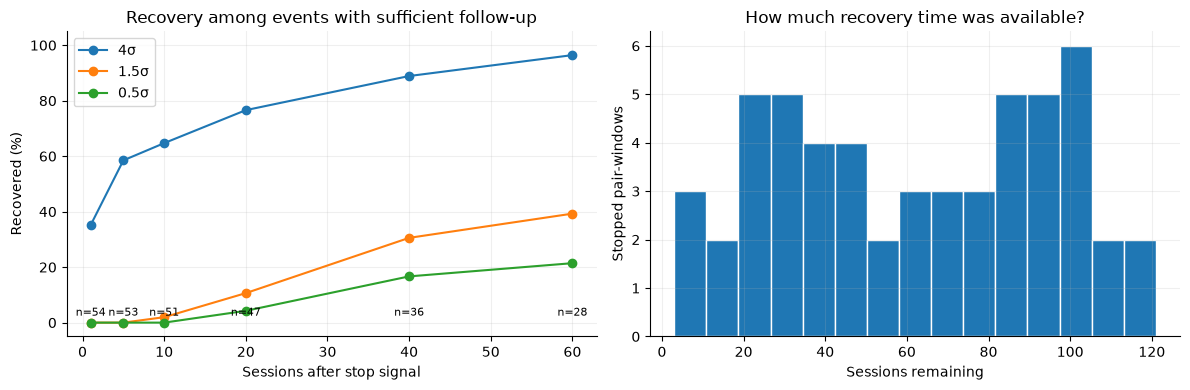

,Stops,Recovery_4,Recovery_1_5,Recovery_0_5
Follow-up group,,,,
1–5,1,1.000000,0.000000,0.000000
6–20,7,0.714286,0.000000,0.000000
21–60,18,0.666667,0.277778,0.166667
61+,28,0.964286,0.607143,0.428571


In [3]:
lag_summary = pd.DataFrame([{'Threshold': h, 'Recovered': int(events[f'Recovered {h:g}'].sum()),
    'Median sessions among recovered': events[f'Lag {h:g}'].median(),
    '25th percentile': events[f'Lag {h:g}'].quantile(.25),
    '75th percentile': events[f'Lag {h:g}'].quantile(.75),
    'Directional crossings': int(events[f'Directional crossing {h:g}'].sum())} for h in THRESHOLDS])
display(lag_summary)
horizon_rows = []
for horizon in [1, 5, 10, 20, 40, 60]:
    eligible = events['Remaining sessions after signal'].ge(horizon)
    for h in THRESHOLDS:
        horizon_rows.append({'Horizon': horizon, 'Threshold': h, 'Eligible stops': int(eligible.sum()),
            'Recovered by horizon': int(events.loc[eligible, f'Lag {h:g}'].le(horizon).sum()),
            'Recovery rate': events.loc[eligible, f'Lag {h:g}'].le(horizon).mean()})
horizons = pd.DataFrame(horizon_rows)
display(horizons)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for h in THRESHOLDS:
    s = horizons.loc[horizons.Threshold.eq(h)]
    axes[0].plot(s.Horizon, s['Recovery rate']*100, marker='o', label=f'{h:g}σ')
for r in horizons.loc[horizons.Threshold.eq(4)].itertuples(index=False):
    axes[0].annotate(f'n={r[2]}', (r[0], 0), xytext=(0, 5), textcoords='offset points', ha='center', fontsize=8)
axes[0].set(xlabel='Sessions after stop signal', ylabel='Recovered (%)', ylim=(-5, 105), title='Recovery among events with sufficient follow-up')
axes[0].legend()
axes[1].hist(events['Remaining sessions after signal'], bins=min(15, len(events)), edgecolor='white')
axes[1].set(xlabel='Sessions remaining', ylabel='Stopped pair-windows', title='How much recovery time was available?')
savefig(fig, 'recovery_timing')
events['Follow-up group'] = pd.cut(events['Remaining sessions after signal'], [0, 5, 20, 60, np.inf],
                                   labels=['1–5', '6–20', '21–60', '61+'])
followup_summary = events.groupby('Follow-up group', observed=True).agg(
    Stops=('Event', 'size'), Recovery_4=('Recovered 4', 'mean'),
    Recovery_1_5=('Recovered 1.5', 'mean'), Recovery_0_5=('Recovered 0.5', 'mean'))
display(followup_summary)


## Divergence, window effects, and individual paths

Separate non-recovery from an additional ≥1σ move away from the mean. The path chart aligns all events at the stop signal and orients the stop side positively; negative values indicate crossing the formation mean. Later quantiles use only events still within their windows, with the sample size shown below. Example paths show the largest subsequent divergence, the fastest 0.5σ recovery, and the stopped event from the most profitable pair across all saved trades (if that pair stopped).

,Stops,Median_peak_abs_z,Maximum_peak_abs_z,Median_final_abs_z,Further_divergence,Median_followup
Never below 4,,,,,,
False,45,5.939295,15.268571,3.642949,27,72.0
True,9,6.911833,18.065571,6.360494,6,30.0


,Stops,Recovered_4,Recovered_1_5,Recovered_0_5,Never_below_4,Median_followup
Window,,,,,,
1,11,9,2,2,2,33.0
2,2,2,0,0,0,68.0
3,1,1,0,0,0,3.0
4,3,3,1,0,0,49.0
5,7,6,5,5,1,72.0
7,6,5,1,1,1,77.0
8,2,2,2,1,0,82.0
9,6,5,5,3,1,82.5
10,2,2,0,0,0,69.0


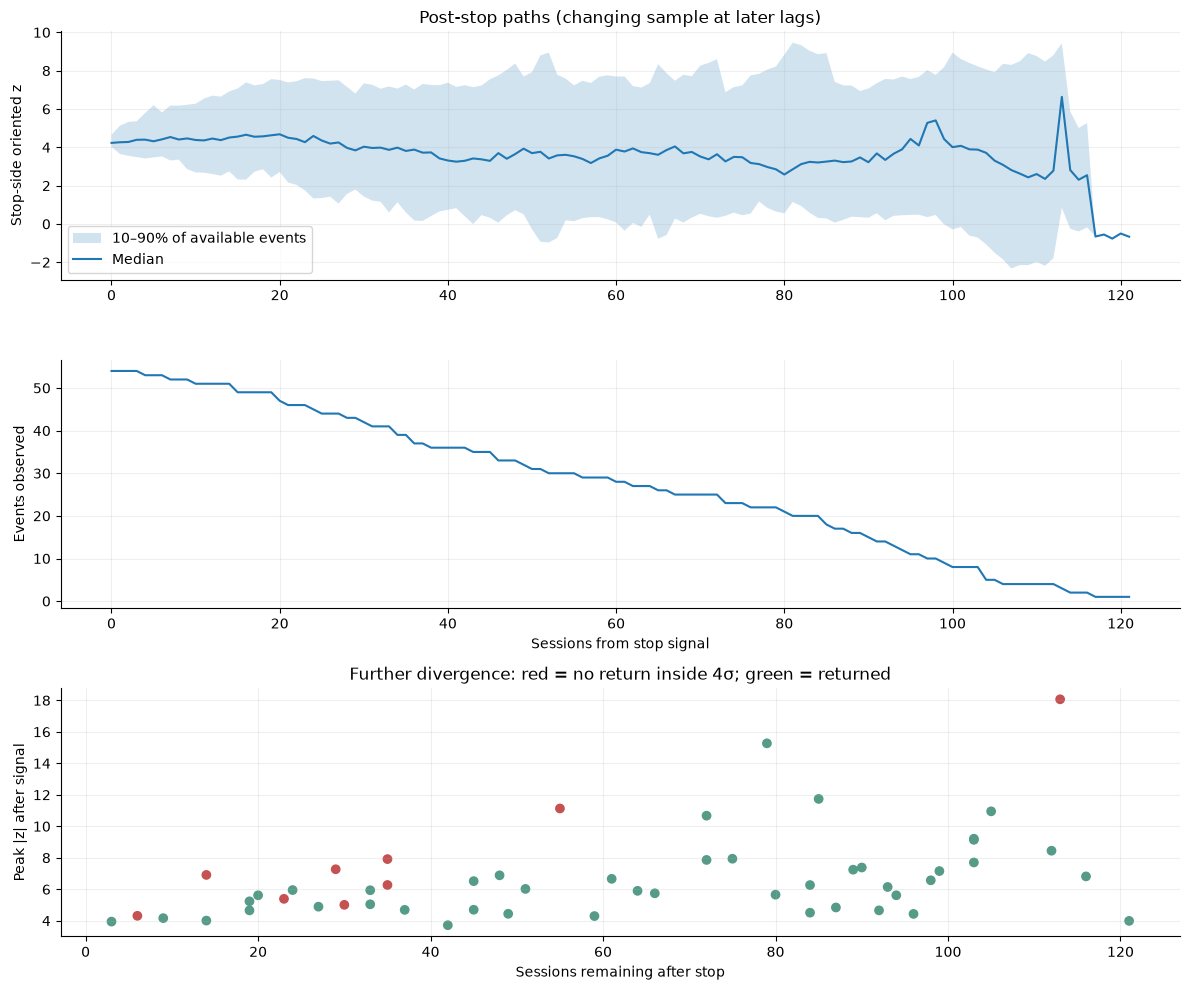

Largest realized pair contribution: MCO / SPGI, $4,129.11


,Event,Window,A,B,Pair,Stop signal,Stop execution,Window end,Clock,Follow-up observations,...,First date 1.5,Lag 1.5,Directional crossing 1.5,Recovered 0.5,First date 0.5,Lag 0.5,Directional crossing 0.5,Never below 4,Further divergence >= 1 sigma,Follow-up group


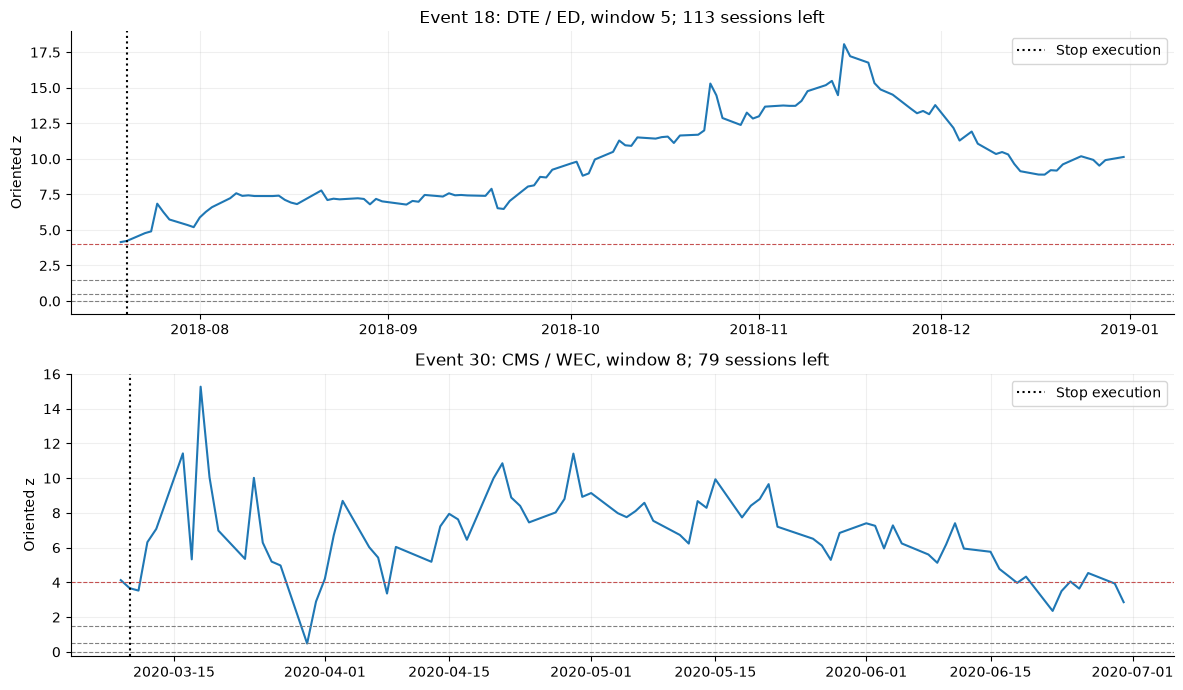

In [4]:
divergence = events.groupby('Never below 4').agg(Stops=('Event', 'size'),
    Median_peak_abs_z=('Peak abs z', 'median'), Maximum_peak_abs_z=('Peak abs z', 'max'),
    Median_final_abs_z=('Final abs z', 'median'),
    Further_divergence=('Further divergence >= 1 sigma', 'sum'),
    Median_followup=('Remaining sessions after signal', 'median'))
display(divergence)
window_stats = events.groupby('Window').agg(Stops=('Event', 'size'),
    Recovered_4=('Recovered 4', 'sum'), Recovered_1_5=('Recovered 1.5', 'sum'),
    Recovered_0_5=('Recovered 0.5', 'sum'), Never_below_4=('Never below 4', 'sum'),
    Median_followup=('Remaining sessions after signal', 'median'))
display(window_stats)
path_records = []
for event, t in stops.iterrows():
    p = paths[tuple(t[k] for k in KEYS)]
    post = p.loc[p.index >= t['Exit Signal Date']]
    for lag, (date, row) in enumerate(post.iterrows()):
        path_records.append({'Event': event, 'Lag': lag, 'Date': date, 'z': row.z,
                             'Oriented z': np.sign(t['Exit Signal z']) * row.z})
aligned = pd.DataFrame(path_records)
q = aligned.groupby('Lag')['Oriented z'].quantile([.1, .5, .9]).unstack()
count = aligned.groupby('Lag').size()
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
axes[0].fill_between(q.index, q[.1], q[.9], alpha=.2, label='10–90% of available events')
axes[0].plot(q.index, q[.5], label='Median')
axes[0].set(ylabel='Stop-side oriented z', title='Post-stop paths (changing sample at later lags)')
axes[0].legend()
axes[1].plot(count.index, count.values)
axes[1].set(xlabel='Sessions from stop signal', ylabel='Events observed')
axes[2].scatter(events['Remaining sessions after signal'], events['Peak abs z'],
                c=np.where(events['Never below 4'], '#c55151', '#559b87'))
axes[2].set(xlabel='Sessions remaining after stop', ylabel='Peak |z| after signal',
            title='Further divergence: red = no return inside 4σ; green = returned')
savefig(fig, 'divergence_and_aligned_paths')

pair_profits = trades.assign(Pair=[' / '.join(sorted([a,b])) for a,b in zip(trades.A, trades.B)]).groupby('Pair')['Net P/L ($)'].sum().sort_values(ascending=False)
best_pair = pair_profits.index[0]
print(f'Largest realized pair contribution: {best_pair}, ${pair_profits.iloc[0]:,.2f}')
best_pair_stops = events.loc[events.Pair.eq(best_pair)]
display(best_pair_stops)
example_ids = [int(events['Peak abs z'].idxmax())]
recovered = events.dropna(subset=['Lag 0.5'])
if len(recovered):
    example_ids.append(int(recovered['Lag 0.5'].idxmin()))
example_ids.extend(best_pair_stops.Event.astype(int).tolist())
example_ids = list(dict.fromkeys(example_ids))[:6]
fig, axes = plt.subplots(len(example_ids), 1, figsize=(12, 3.5*len(example_ids)), squeeze=False)
for ax, event in zip(axes.flat, example_ids):
    e = events.loc[event]
    s = aligned.loc[aligned.Event.eq(event)]
    ax.plot(s.Date, s['Oriented z'])
    for h in [0, .5, 1.5, 4]:
        ax.axhline(h, color='gray' if h != 4 else '#c55151', ls='--', lw=.8)
    ax.axvline(e['Stop execution'], color='black', ls=':', label='Stop execution')
    ax.set(title=f"Event {event}: {e.Pair}, window {e.Window}; {e['Remaining sessions after signal']} sessions left", ylabel='Oriented z')
    ax.legend()
savefig(fig, 'example_paths')


## Alternative blacklist mechanisms: opportunity and relapse screens

Compare permanent blacklisting with a 5-session cooldown and resets after returning inside 4σ, 1.5σ, or 0.5σ. Each candidate uses only the current and past closes: after the first reset, the blacklist stays cleared. A reset on a signal close can first affect an order at the following close. A stop-day close is never a reset; an execution-day close can be.

We report how many events would clear the blacklist with an executable entry signal later in the same window, the delay to that first signal, and how often the original stop side is breached again **after reset**. Entry opportunities use the saved entry/stop band; exclude the final session because no next-close execution remains. These are eligibility screens, not hypothetical trades: they do not simulate positions, re-stops, repeated resets, allocation, or P&L. A 0.5σ reset needs a later move back to the entry band. Recovery alone cannot establish that re-entry would be profitable.

,Stops,Reset_events,Events_with_entry_opportunity,Median_sessions_to_first_signal,Events_rebreaching_original_stop
Policy,,,,,
Permanent,54,0,0,NaN,0
Cooldown 5,54,53,41,8.0,49
Reset 4,54,45,45,2.0,40
Reset 1.5,54,22,20,45.0,5
Reset 0.5,54,15,10,42.5,3


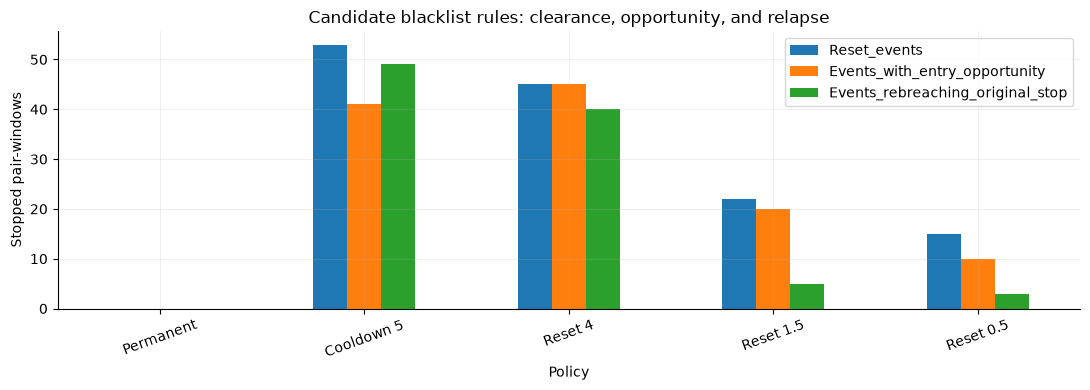

In [5]:
policy_rows = []
for event, t in stops.iterrows():
    p = paths[tuple(t[k] for k in KEYS)]
    post = p.loc[p.index > t['Exit Signal Date']]
    full_dates = p.index
    for policy in ['Permanent', 'Cooldown 5', 'Reset 4', 'Reset 1.5', 'Reset 0.5']:
        if policy == 'Permanent':
            hits = np.array([], dtype=int)
        elif policy == 'Cooldown 5':
            hits = np.flatnonzero(np.arange(1, len(post)+1) >= 5)
        else:
            hits = np.flatnonzero(band(post.z.to_numpy(), float(policy.split()[1])))
        reset_date = post.index[hits[0]] if len(hits) else pd.NaT
        candidates = p.loc[(p.index >= reset_date) & (p.index < full_dates[-1])] if pd.notna(reset_date) else p.iloc[:0]
        eligible = candidates.loc[candidates.z.abs().ge(params['entry_z']) & candidates.z.abs().lt(params['stop_z'])]
        first_signal = eligible.index[0] if len(eligible) else pd.NaT
        after_reset = p.loc[p.index > reset_date] if pd.notna(reset_date) else p.iloc[:0]
        relapse = (np.sign(t['Exit Signal z']) * after_reset.z).ge(params['stop_z']).any()
        policy_rows.append({'Event': event, 'Policy': policy, 'Reset date': reset_date,
            'Executable entry signal date': first_signal, 'Eligible signal closes': len(eligible),
            'Sessions to first signal': int(full_dates.get_loc(first_signal) - full_dates.get_loc(t['Exit Signal Date'])) if pd.notna(first_signal) else np.nan,
            'Original-side stop breach after reset': bool(relapse) if pd.notna(reset_date) else np.nan})
policy_events = pd.DataFrame(policy_rows)
policy_summary = policy_events.groupby('Policy', sort=False).agg(
    Stops=('Event', 'size'), Reset_events=('Reset date', 'count'),
    Events_with_entry_opportunity=('Executable entry signal date', 'count'),
    Median_sessions_to_first_signal=('Sessions to first signal', 'median'),
    Events_rebreaching_original_stop=('Original-side stop breach after reset', 'sum'))
display(policy_summary)
fig, ax = plt.subplots()
policy_summary[['Reset_events', 'Events_with_entry_opportunity', 'Events_rebreaching_original_stop']].plot.bar(ax=ax)
ax.set(ylabel='Stopped pair-windows', title='Candidate blacklist rules: clearance, opportunity, and relapse')
ax.tick_params(axis='x', rotation=20)
savefig(fig, 'blacklist_policy_screens')


## Findings and reproducible exports

Use recovery timing together with the remaining-session distribution and relapse counts when choosing mechanisms for a later full backtest. Window-level counts help reveal whether a few market episodes dominate. Repeated pairs and correlated stocks mean events are not independent; these descriptive rates have no independence-based significance claim. Strategy selection and choosing reset rules from this sample both require subsequent validation.

In [6]:
display(Markdown(f"Of **{len(events)}** stopped pair-windows, **{events['Recovered 4'].sum()}** returned inside 4σ, "
    f"**{events['Recovered 1.5'].sum()}** reached ±1.5σ, and **{events['Recovered 0.5'].sum()}** reached ±0.5σ. "
    f"**{events['Never below 4'].sum()}** never returned inside 4σ before their trading window ended. "
    f"Among those non-recoveries, **{(events['Never below 4'] & events['Further divergence >= 1 sigma']).sum()}** "
    'also diverged at least another 1σ beyond their stop-signal distance.'))
for name, frame, index in [
    ('stop_events', events, False), ('execution_clock_events', execution_events, False),
    ('recovery_summary', recovery_summary, True), ('recovery_lags', lag_summary, False),
    ('horizon_recovery', horizons, False), ('followup_summary', followup_summary, True),
    ('window_summary', window_stats, True), ('divergence_summary', divergence, True),
    ('policy_events', policy_events, False), ('policy_summary', policy_summary, True),
    ('blacklists_without_stop_exit', unexecuted, False), ('aligned_paths', aligned, False)]:
    frame.to_csv(OUT / (name + '.csv'), index=index)
manifest = {'source_run': run.name, 'source_folder': folder.name, 'parameters': params,
    'saved_sharpe': float(winner['Sharpe Ratio']), 'stop_events': len(events),
    'thresholds': THRESHOLDS, 'primary_clock': 'strictly after stop signal, same window only',
    'execution_clock': 'execution close inclusive',
    'band_definition': '|z| < 4; |z| <= 1.5 and 0.5; observed closes only',
    'figures': figures, 'policy_scope': 'eligibility diagnostics only, no counterfactual P&L',
    'sha256': {name: hashlib.sha256((folder / name).read_bytes()).hexdigest()
               for name in ['grid_summary.csv'] if (folder / name).exists()}}
manifest['sha256'].update({name: hashlib.sha256((folder / name).read_bytes()).hexdigest()
    for name in ['trades.csv', 'pair_daily.csv.gz', 'parameters.json', 'window_summary.csv']})
manifest['sha256']['grid_summary.csv'] = hashlib.sha256((run / 'grid_summary.csv').read_bytes()).hexdigest()
(OUT / 'analysis_manifest.json').write_text(json.dumps(manifest, indent=2))
print(f'Saved tables, event audits, figures, and source hashes to {OUT.relative_to(ROOT)}')


Of **54** stopped pair-windows, **45** returned inside 4σ, **22** reached ±1.5σ, and **15** reached ±0.5σ. **9** never returned inside 4σ before their trading window ended. Among those non-recoveries, **6** also diverged at least another 1σ beyond their stop-signal distance.

Saved tables, event audits, figures, and source hashes to outputs/blacklist_diagnostics_zero_cost/cb64c19613e1e11beb71/formation_months_18_trading_months_6_correlation_threshold_0.8_eg_significance_0.01_entry_z_1.5_exit_z_0.5_stop_z_4
